# MSSearch Next-Gen Redesign: Multi-Stage Diagnostic & Visual Inspection Notebook
## Continuous Posterior Evidence Allocation, Dense Spatial Token Saliency & Macro-Scale Consolidation

This diagnostic notebook implements, executes, and visualizes the first-principles architectural redesign of **MSSearch** across:
- **Stage 1 (Dual-Granularity Semantic Decomposition)**: Decoupling question parsing into **Atomic Visual Anchors** $\mathcal{V}_q$ (for SAM3/VLM existence) and **Dense Semantic Target Queries** $\mathcal{A}_q$ (for SigLIP), enforcing strict string binding (`label_str: str`) to eliminate integer class ID casting and linguistic prompt distraction.
- **Stage 3 (Dense Spatial Token Saliency & Scale-Entropy Regularized Stopping Criterion)**: Extracting pre-pooling $24 \times 24$ ViT spatial token grids $\mathbf{F}_p$ from SigLIP to measure peak token concentration $S^*(p)$ (preventing micro-object dilution at $>512\text{px}$), paired with an **Upper Confidence Bound (UCB)** stopping criterion $\Gamma(p) = \Delta S^*(p) + \lambda_{\text{scale}} H(p) \frac{L_p - 512}{1024}$ to eliminate premature plateau freezes on complex crops.
- **Stage 4 (Continuous Bayesian Evidential Consolidation & Macro-Object Coverage)**: Replacing destructive binary gating (`PRUNED`) with continuous posterior scoring $E_{\text{post}}(p) = E_{\text{prior}}(p) + \beta c_{\text{VLM}}(p_m^*)$ evaluated on the **Argmax Evidential Peak** $p_m^*$ (not centroid), and merging adjacent member patches into unified macro-envelopes (preventing 50–90% target truncation on buses/trains/signs).

**Execution Contract**: Designed for dual-GPU Kaggle environments (GPU 0: SigLIP + Qwen2.5-VL, GPU 1: SAM3). Because visual search benchmarks do not provide ground-truth bounding boxes, this notebook provides end-to-end qualitative overlays, spatial token heatmaps, Bayesian delta cards, and macro-object envelope visualizations.


In [1]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP, GITHUB REPO SYNC & HARDWARE TELEMETRY
# ==============================================================================
import os
import sys
import gc
import json
import re
import time
import subprocess
import importlib
import urllib.request
from typing import List, Dict, Tuple, Optional, Any

import numpy as np
import torch
import torch.nn as nn
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

REPO_DIR = "/kaggle/working/MSSearch"
github_token = None

# Retrieve GitHub Access Token from Kaggle User Secrets
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    github_token = user_secrets.get_secret("MaCVi")
    print("[SETUP] Successfully retrieved GitHub token from Kaggle User Secret 'MaCVi'.")
except Exception as e:
    github_token = os.environ.get("MaCVi") or os.environ.get("GITHUB_TOKEN")

if not os.path.exists(REPO_DIR):
    if github_token:
        print(f"[SETUP] Cloning MSSearch repository using authenticated token into {REPO_DIR}...")
        clone_url = f"https://{github_token}@github.com/tothanhdat2006/MSSearch.git"
    else:
        print(f"[SETUP] 'MaCVi' secret not found. Attempting unauthenticated clone into {REPO_DIR}...")
        clone_url = "https://github.com/tothanhdat2006/MSSearch.git"
    
    ret = subprocess.run(["git", "clone", clone_url, REPO_DIR], capture_output=True, text=True)
    if ret.returncode == 0:
        print(f"[SETUP] Successfully cloned MSSearch repository into {REPO_DIR}")
    else:
        safe_err = ret.stderr.replace(github_token, "******") if github_token else ret.stderr
        print(f"[SETUP] Git clone failed: {safe_err}")
else:
    print(f"[SETUP] MSSearch repository already exists at {REPO_DIR}. Pulling latest changes from main...")
    ret = subprocess.run(["git", "-C", REPO_DIR, "pull", "origin", "main"], capture_output=True, text=True)
    if ret.returncode == 0:
        print(f"[SETUP] Repository successfully updated to latest commit: {ret.stdout.strip()}")

# Ensure REPO_DIR is at the front of sys.path
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
elif sys.path[0] != REPO_DIR:
    sys.path.remove(REPO_DIR)
    sys.path.insert(0, REPO_DIR)

importlib.invalidate_caches()
for mod in list(sys.modules.keys()):
    if mod.startswith("mssearch"):
        del sys.modules[mod]

# Ensure BPE vocab file is present for SAM3 tokenizer
bpe_target = os.path.join(REPO_DIR, "assets", "bpe_simple_vocab_16e6.txt.gz")
if not os.path.exists(bpe_target):
    os.makedirs(os.path.dirname(bpe_target), exist_ok=True)
    bpe_url = "https://raw.githubusercontent.com/openai/CLIP/main/clip/bpe_simple_vocab_16e6.txt.gz"
    print(f"[SETUP] Downloading missing BPE vocab to {bpe_target}...")
    try:
        urllib.request.urlretrieve(bpe_url, bpe_target)
        print("[SETUP] Successfully downloaded BPE vocab asset.")
    except Exception as e:
        print(f"[SETUP WARNING] BPE download failed: {e}")

# Install dependencies
!pip install -q "transformers>=4.45.0" "accelerate>=0.26.0" "tabulate" iopath decord ftfy scikit-image scikit-learn networkx

# Hardware Telemetry
device_count = torch.cuda.device_count()
print("=" * 75)
print(f"PyTorch Version:  {torch.__version__}")
print(f"CUDA Available:   {torch.cuda.is_available()}")
print(f"GPU Device Count: {device_count}")
for i in range(device_count):
    prop = torch.cuda.get_device_properties(i)
    free_mem, total_mem = torch.cuda.mem_get_info(i)
    print(f"  [GPU {i}] {prop.name} | Total: {total_mem/(1024**3):.2f} GiB | Free: {free_mem/(1024**3):.2f} GiB")
print("=" * 75)


[SETUP] Successfully retrieved GitHub token from Kaggle User Secret 'MaCVi'.
[SETUP] Cloning MSSearch repository using authenticated token into /kaggle/working/MSSearch...
[SETUP] Successfully cloned MSSearch repository into /kaggle/working/MSSearch
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PyTorch Version:  2.11.0+cu128
CUDA Available:   True
GPU Device Count: 2
  [GPU 0] Tesla T4 | Total: 14.56 GiB | Free: 14.46 GiB
  [GPU 1] Tesla T4 | Total: 14.56 GiB | Free: 14.46 GiB


[Dataset Discovery] Using HRBench root: /kaggle/input/datasets/thnhtt/vs-dataset/hr-bench_8k/mnt/sdb/llp/datasets/zoom_eye_data/zoom_eye_data/hr-bench_8k
[Dataset Discovery] Loading annotations: /kaggle/input/datasets/thnhtt/vs-dataset/hr-bench_8k/mnt/sdb/llp/datasets/zoom_eye_data/zoom_eye_data/hr-bench_8k/annotation_hr-bench_8k.json
[Dataset] Ingested 200 total samples.
[Target Sample 2] Question: 'Is the mailbox on the left or right side of the woman?'
[Target Sample 2] Ground Truth: Option 'A'
[Sampling] Distractor indices sampled within +/- 10: [11, 1]
[Candidate Pool C] Total N = 3 images constructed.
[Candidate Pool C] Target image is positioned at Pool Index: 2
  - Image 0: [DISTRACTOR] Sample #1 | Path: 'image/4.jpg' | Size: (4992, 7680)
  - Image 1: [DISTRACTOR] Sample #11 | Path: 'image/44.jpg' | Size: (7680, 4992)
  - Image 2: [TARGET] Sample #2 | Path: 'image/8.jpg' | Size: (4992, 7680)


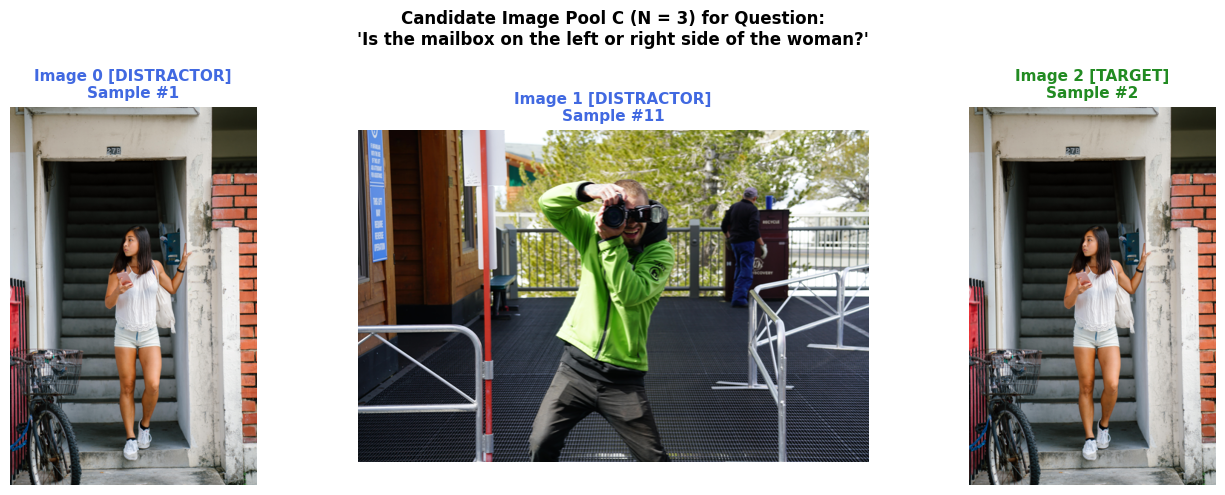

In [2]:
# ==============================================================================
# CELL 2: MULTI-SOURCE DATASET INGESTION & N-IMAGE CANDIDATE POOL SAMPLING
# ==============================================================================
import os
import json
import random
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt

HRBENCH_SEARCH_DIRS = [
    "D:/Research/VisualSearch/hr-bench_8k",
    "d:/Research/VisualSearch/hr-bench_8k",
    "/kaggle/input/datasets/thnhtt/vs-dataset/hr-bench_8k/mnt/sdb/llp/datasets/zoom_eye_data/zoom_eye_data/hr-bench_8k",
    "/kaggle/input/datasets/thnhtt/vs-dataset/hr-bench_8k",
    "/kaggle/input/datasets/thnhtt/vs-dataset/hr-bench_4k",
    "/kaggle/input/hr-bench-8k",
    "/kaggle/input/hr-bench-4k",
    "docs/experiments/multisource/data/hr-bench_8k",
    "docs/experiments/freeform/ICML26-CVSearch/data/hr-bench_8k"
]

HRBENCH_BASE_DIR = None
for d in HRBENCH_SEARCH_DIRS:
    if os.path.exists(d):
        HRBENCH_BASE_DIR = d
        break

if HRBENCH_BASE_DIR is None:
    raise FileNotFoundError(f"[Dataset Error] Could not find HRBench directory in candidate paths: {HRBENCH_SEARCH_DIRS}")

HRBENCH_ANNOTATION_PATH = os.path.join(HRBENCH_BASE_DIR, "annotation_hr-bench_8k.json")
if not os.path.exists(HRBENCH_ANNOTATION_PATH):
    HRBENCH_ANNOTATION_PATH = os.path.join(HRBENCH_BASE_DIR, "annotation_hr-bench_4k.json")

print(f"[Dataset Discovery] Using HRBench root: {HRBENCH_BASE_DIR}")
print(f"[Dataset Discovery] Loading annotations: {HRBENCH_ANNOTATION_PATH}")

with open(HRBENCH_ANNOTATION_PATH, "r", encoding="utf-8") as f:
    hrbench_data = json.load(f)

print(f"[Dataset] Ingested {len(hrbench_data)} total samples.")

# ------------------------------------------------------------------------------
# MULTI-SOURCE CONFIGURATION KNOBS
# ------------------------------------------------------------------------------
SAMPLE_INDEX = 2             # Primary target sample index (e.g. 0, 1, 2...)
NUM_CANDIDATE_IMAGES = 3     # N images (1 target + N-1 distractors)
WINDOW_SIZE = 10              # Local index sampling window: [SAMPLE_INDEX - 5, SAMPLE_INDEX + 5]
RANDOM_SEED = 42             # Deterministic sampling & shuffling seed

target_sample = hrbench_data[SAMPLE_INDEX]
real_question = target_sample.get('question', '')
cycle_idx = target_sample.get('cycle_category', 0)
gt_answer = target_sample.get('answer', '')

def resolve_gt_letter(answer_obj, cycle_idx=0):
    if isinstance(answer_obj, list):
        if 0 <= cycle_idx < len(answer_obj):
            return str(answer_obj[cycle_idx]).strip().upper()
        return str(answer_obj[0]).strip().upper() if answer_obj else ""
    return str(answer_obj).strip().upper()

gt_letter = resolve_gt_letter(gt_answer, cycle_idx)
raw_options = target_sample.get('options', {})

print("=" * 75)
print(f"[Target Sample {SAMPLE_INDEX}] Question: '{real_question}'")
print(f"[Target Sample {SAMPLE_INDEX}] Ground Truth: Option '{gt_letter}'")
print("=" * 75)

# Load Target Image
target_img_rel = target_sample.get('input_image', '')
target_img_path = os.path.join(HRBENCH_BASE_DIR, target_img_rel)
if not os.path.exists(target_img_path):
    target_img_path = target_img_rel
target_canvas = Image.open(target_img_path).convert("RGB")

# Sample (N - 1) Distractor Images
total_samples = len(hrbench_data)
min_win = max(0, SAMPLE_INDEX - WINDOW_SIZE)
max_win = min(total_samples - 1, SAMPLE_INDEX + WINDOW_SIZE)

candidate_distractor_indices = [
    idx for idx in range(min_win, max_win + 1) if idx != SAMPLE_INDEX
]
if len(candidate_distractor_indices) < (NUM_CANDIDATE_IMAGES - 1):
    candidate_distractor_indices = [
        idx for idx in range(total_samples) if idx != SAMPLE_INDEX
    ]

rng = random.Random(RANDOM_SEED)
sampled_distractor_indices = rng.sample(candidate_distractor_indices, NUM_CANDIDATE_IMAGES - 1)
print(f"[Sampling] Distractor indices sampled within +/- {WINDOW_SIZE}: {sampled_distractor_indices}")

pool_items = [
    {"is_target": True, "sample_idx": SAMPLE_INDEX, "image": target_canvas, "path": target_img_rel}
]

for d_idx in sampled_distractor_indices:
    d_sample = hrbench_data[d_idx]
    d_rel = d_sample.get('input_image', '')
    d_path = os.path.join(HRBENCH_BASE_DIR, d_rel)
    if not os.path.exists(d_path):
        d_path = d_rel
    d_img = Image.open(d_path).convert("RGB")
    pool_items.append({
        "is_target": False, "sample_idx": d_idx, "image": d_img, "path": d_rel
    })

rng.shuffle(pool_items)
candidate_images = [item["image"] for item in pool_items]
target_pool_idx = next(i for i, item in enumerate(pool_items) if item["is_target"])

print(f"[Candidate Pool C] Total N = {len(candidate_images)} images constructed.")
print(f"[Candidate Pool C] Target image is positioned at Pool Index: {target_pool_idx}")
for idx, item in enumerate(pool_items):
    tag = "TARGET" if item["is_target"] else "DISTRACTOR"
    print(f"  - Image {idx}: [{tag}] Sample #{item['sample_idx']} | Path: '{item['path']}' | Size: {item['image'].size}")

# Side-by-Side Thumbnail Visualization of Candidate Pool
fig, axes = plt.subplots(1, len(candidate_images), figsize=(5 * len(candidate_images), 5))
if len(candidate_images) == 1:
    axes = [axes]

for i, (ax, item) in enumerate(zip(axes, pool_items)):
    thumb = item["image"].copy()
    thumb.thumbnail((512, 512))
    ax.imshow(thumb)
    is_t = item["is_target"]
    color = "forestgreen" if is_t else "royalblue"
    label = f"Image {i} [TARGET]\nSample #{item['sample_idx']}" if is_t else f"Image {i} [DISTRACTOR]\nSample #{item['sample_idx']}"
    ax.set_title(label, fontsize=11, fontweight="bold", color=color)
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(3)

plt.suptitle(f"Candidate Image Pool C (N = {len(candidate_images)}) for Question:\n'{real_question}'", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


In [3]:
# ==============================================================================
# CELL 3: FOUNDATION MODEL INITIALIZATION & DUAL-GPU ALLOCATION
# ==============================================================================
import os
import sys
import gc
import json
import torch
from PIL import Image

from mssearch.config import MSSearchConfig
from mssearch.models.modeling_sam3 import sam3_inference
from mssearch.models.modeling_siglip import SigLIPScorer
from mssearch.models.modeling_qwenvl import ModelQwenVL
from mssearch.stages.stage2_fast_path import run_direct_global_assessment, run_tool_based_fast_path

# 1. Discover SAM3 Weights
SAM3_CHECKPOINT_PATH = "/kaggle/input/datasets/thnhtt/vs-sam3/sam3/sam3/sam3.pt"
if not os.path.exists(SAM3_CHECKPOINT_PATH):
    for root, _, files in os.walk("/kaggle/input"):
        for f in files:
            if f == "sam3.pt":
                SAM3_CHECKPOINT_PATH = os.path.join(root, f)
                break
        if os.path.exists(SAM3_CHECKPOINT_PATH):
            break

if not os.path.exists(SAM3_CHECKPOINT_PATH):
    raise FileNotFoundError(f"[Model Discovery Error] SAM3 checkpoint not found at '{SAM3_CHECKPOINT_PATH}'.")

print(f"[Model Discovery] SAM3 Weights: {SAM3_CHECKPOINT_PATH}")

# 2. Discover Qwen2.5-VL Weights (Local Kaggle Dataset or HF Hub ID)
QWEN_MODEL_PATH = "Qwen/Qwen2.5-VL-7B-Instruct"
for root, _, files in os.walk("/kaggle/input"):
    if "config.json" in files:
        try:
            with open(os.path.join(root, "config.json"), "r", encoding="utf-8") as f:
                c = json.load(f)
                if c.get("model_type") in ("qwen2_5_vl", "qwen2_vl") or any("Qwen2" in a for a in c.get("architectures", [])):
                    QWEN_MODEL_PATH = root
                    print(f"[Model Discovery] Found local Qwen2.5-VL weights at: {QWEN_MODEL_PATH}")
                    break
        except Exception:
            pass

# 3. Asymmetric Dual-GPU Allocation
num_gpus = torch.cuda.device_count()
sam3_device = "cuda:1" if num_gpus > 1 else ("cuda:0" if num_gpus > 0 else "cpu")
siglip_device = "cuda:0" if num_gpus > 0 else "cpu"
qwen_device = "cuda:0" if num_gpus > 0 else "cpu"

print(f"[Hardware Topology] Detected {num_gpus} GPUs. Allocation:")
print(f"  - SAM3 Engine      : {sam3_device}")
print(f"  - SigLIP-SO400M    : {siglip_device}")
print(f"  - Qwen2.5-VL Engine: {qwen_device}")

# 4. Load Model Weights
print(f"[Loading] SAM3 Local Segmenter on {sam3_device}...")
sam3_engine = sam3_inference(model_path=SAM3_CHECKPOINT_PATH, device=sam3_device)
print("  [Loaded] SAM3 Local Segmenter Engine")

print(f"[Loading] SigLIP-SO400M on {siglip_device}...")
siglip_engine = SigLIPScorer(model_name="google/siglip-base-patch16-384", device=siglip_device, torch_dtype=torch.float16)
siglip_engine._ensure_loaded()
print("  [Loaded] SigLIP Saliency & Verification Engine")

print(f"[Loading] Qwen2.5-VL-7B-Instruct from '{QWEN_MODEL_PATH}' on {qwen_device}...")
qwen_engine = ModelQwenVL(
    model_path=QWEN_MODEL_PATH,
    device=qwen_device,
    torch_dtype=torch.float16,
    patch_scale=1.2,
    local_files_only=os.path.exists(QWEN_MODEL_PATH)
)
print("  [Loaded] Qwen2.5-VL Multi-Scale Reader Engine")

# Base configuration with scaled budgets
config_redesign = MSSearchConfig(
    multi_answer_mode=True,
    scale_budgets_by_num_images=True,
    max_sam3_eval_patches=32 * NUM_CANDIDATE_IMAGES,
    max_latent_evals=32 * NUM_CANDIDATE_IMAGES,
    max_retained_patches=5 * NUM_CANDIDATE_IMAGES,
    min_patch_entropy=0.35,
    verbose=True
)

print("[CONFIG] MSSearch Redesign Config successfully instantiated.")


[Model Discovery] SAM3 Weights: /kaggle/input/datasets/thnhtt/vs-sam3/sam3/sam3/sam3.pt
[Hardware Topology] Detected 2 GPUs. Allocation:
  - SAM3 Engine      : cuda:1
  - SigLIP-SO400M    : cuda:0
  - Qwen2.5-VL Engine: cuda:0
[Loading] SAM3 Local Segmenter on cuda:1...
[sam3_inference] Binding SAM3 to device: cuda:1 (Weights: /kaggle/input/datasets/thnhtt/vs-sam3/sam3/sam3/sam3.pt)


  [Loaded] SAM3 Local Segmenter Engine
[Loading] SigLIP-SO400M on cuda:0...
[SigLIPScorer] Loading 'google/siglip-base-patch16-384' on cuda:0 (torch.float16)...


config.json:   0%|          | 0.00/322 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  814MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

... (17 outputs left out)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

[ModelQwenVL] Successfully loaded model as Qwen2_5_VLForConditionalGeneration
[ModelQwenVL] Injected processor.patch_size = 14
[ModelQwenVL] max_pixels capped at: 12845056
[ModelQwenVL] min_pixels: 3136
bias_value: 0.6
input size: (448, 448)
background color: (122, 116, 104)
patch scale: 1.2
index_yes: 9454
index_no: 2753
  [Loaded] Qwen2.5-VL Multi-Scale Reader Engine
[CONFIG] MSSearch Redesign Config successfully instantiated.


STAGE 1 DUAL-GRANULARITY OUTPUT (Latency: 33.588s)
  • Atomic Visual Anchors V_q   : ['mailbox', 'woman']
  • Dense Semantic Queries A_q : ['mailbox near woman']
  • Target Entity              : 'mailbox'
  • Anchor Entity              : 'woman'
  • Is Relational Query        : True (Predicate: 'left of')
  • Canonical String ID Map    : {'obj_1': 'mailbox', 'obj_2': 'woman'}


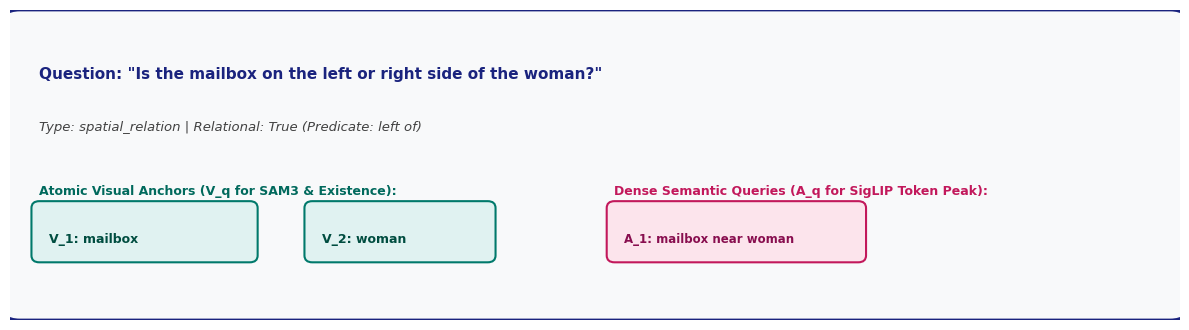

In [4]:
# ==============================================================================
# CELL 4: STAGE 1 — DUAL-GRANULARITY SEMANTIC DECOMPOSITION & STRING BINDING
# ==============================================================================
# Resolving Problems:
#   #5 (SAM3 Open-Vocabulary Mismatch)
#   #7 (Representative Patch Mismatch & Integer ID Bug)
#   #8 (Linguistic Distraction from Attribute Prompts)
# ==============================================================================
import json
import re
from dataclasses import dataclass, field

@dataclass
class DualGranularityParse:
    question: str
    atomic_visual_anchors: List[str]  # V_q: concrete physical nouns for SAM3 and existence checks
    dense_semantic_queries: List[str] # A_q: compositional phrases (host + target) for SigLIP
    target_entity: str
    anchor_entity: Optional[str]
    is_relational: bool
    spatial_predicate: Optional[str]
    question_type: str
    string_id_map: Dict[str, str] = field(default_factory=dict) # Strict natural string mapping

def parse_question_dual_granularity(
    question: str,
    vlm_model: Any,
    verbose: bool = True
) -> DualGranularityParse:
    """
    Extracts two decoupled semantic levels:
      1. Atomic Visual Anchors (V_q): Concrete physical nouns without relational clutter,
         used strictly by SAM3 and existence calibration prompts.
      2. Dense Semantic Queries (A_q): Compositional host+target phrases,
         used by SigLIP dense token-grid peak scoring.
    """
    prompt = f"""You are a precision visual search query parser. Analyze the question below and extract a structured JSON representation:

Question: "{question}"

Instructions:
1. "atomic_visual_anchors": List 1 to 3 isolated, concrete, visually localizable nouns representing physical objects or their structural hosts (e.g. ["car", "wheel", "signboard", "plaque", "jacket"]). Strip out colors, adjectives, relative directions ("left of", "near"), and question preambles.
2. "dense_semantic_queries": List 1 to 3 full semantic visual descriptions of the targets, pairing fine targets with their local hosts or context (e.g. ["registration number on boat", "license plate on front bumper", "small plaque above doorway"]).
3. "target_entity": The primary physical noun whose properties or text answer the question.
4. "anchor_entity": The secondary reference object if a spatial relationship exists, else null.
5. "is_relational": True if answering requires determining relative position between two distinct objects (e.g. "which car is left of the tree", "number above entrance"), else False.
6. "spatial_predicate": The relational preposition/phrase (e.g. "above", "left of", "in front of"), else null.
7. "question_type": One of ["attribute", "text_reading", "counting", "spatial_relation", "identification"].

Return ONLY valid JSON matching this schema:
{{
  "atomic_visual_anchors": ["..."],
  "dense_semantic_queries": ["..."],
  "target_entity": "...",
  "anchor_entity": null,
  "is_relational": false,
  "spatial_predicate": null,
  "question_type": "..."
}}
"""
    try:
        if hasattr(vlm_model, "get_response"):
            raw_response = vlm_model.get_response(prompt=prompt, max_new_tokens=256)
        elif hasattr(vlm_model, "generate_text"):
            raw_response = vlm_model.generate_text(prompt=prompt, max_new_tokens=256)
        else:
            raise AttributeError("VLM model has neither get_response nor generate_text")
        cleaned = re.sub(r'```json\s*', '', raw_response)
        cleaned = re.sub(r'```', '', cleaned).strip()
        data = json.loads(cleaned)
    except Exception as e:
        if verbose:
            print(f"[Stage 1 Fallback] JSON parse failed: {e}. Using rule-based fallback.")
        data = {
            "atomic_visual_anchors": ["object"],
            "dense_semantic_queries": [question[:60]],
            "target_entity": "object",
            "anchor_entity": None,
            "is_relational": False,
            "spatial_predicate": None,
            "question_type": "general"
        }

    # Strict Symbolic String Binding: map each anchor to a canonical label string
    anchors = data.get("atomic_visual_anchors", ["object"])
    id_map = {f"obj_{i+1}": str(a).strip().lower() for i, a in enumerate(anchors)}

    result = DualGranularityParse(
        question=question,
        atomic_visual_anchors=anchors,
        dense_semantic_queries=data.get("dense_semantic_queries", [question]),
        target_entity=data.get("target_entity", anchors[0] if anchors else "object"),
        anchor_entity=data.get("anchor_entity"),
        is_relational=bool(data.get("is_relational", False)),
        spatial_predicate=data.get("spatial_predicate"),
        question_type=data.get("question_type", "unknown"),
        string_id_map=id_map
    )
    return result

# Execute Stage 1 Dual-Granularity Parsing
t0_s1 = time.perf_counter()
stage1_parsed = parse_question_dual_granularity(
    question=real_question,
    vlm_model=qwen_engine,
    verbose=True
)
t_s1 = time.perf_counter() - t0_s1

print("=" * 75)
print(f"STAGE 1 DUAL-GRANULARITY OUTPUT (Latency: {t_s1:.3f}s)")
print("=" * 75)
print(f"  • Atomic Visual Anchors V_q   : {stage1_parsed.atomic_visual_anchors}")
print(f"  • Dense Semantic Queries A_q : {stage1_parsed.dense_semantic_queries}")
print(f"  • Target Entity              : '{stage1_parsed.target_entity}'")
print(f"  • Anchor Entity              : '{stage1_parsed.anchor_entity}'")
print(f"  • Is Relational Query        : {stage1_parsed.is_relational} (Predicate: '{stage1_parsed.spatial_predicate}')")
print(f"  • Canonical String ID Map    : {stage1_parsed.string_id_map}")

# Diagnostic Visualization Card
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.set_xlim(0, 12)
ax.set_ylim(0, 3.6)
ax.axis('off')

card = mpatches.FancyBboxPatch((0.1, 0.2), 11.8, 3.2, boxstyle="round,pad=0.2",
                               edgecolor='#1a237e', facecolor='#f8f9fa', linewidth=2.0)
ax.add_patch(card)

ax.text(0.3, 2.8, f'Question: "{real_question}"', fontsize=11, fontweight='bold', color='#1a237e')
ax.text(0.3, 2.2, f"Type: {stage1_parsed.question_type} | Relational: {stage1_parsed.is_relational} (Predicate: {stage1_parsed.spatial_predicate})", 
        fontsize=9.5, color='#424242', style='italic')

# Chips for Atomic Visual Anchors (V_q)
chips_x = 0.3
ax.text(chips_x, 1.45, "Atomic Visual Anchors (V_q for SAM3 & Existence):", fontsize=9.0, fontweight='bold', color='#00695c')
chips_x += 0.0
for i, anchor in enumerate(stage1_parsed.atomic_visual_anchors):
    chip = mpatches.FancyBboxPatch((chips_x + i * 2.8, 0.75), len(anchor) * 0.18 + 0.9, 0.55,
                                   boxstyle="round,pad=0.08", edgecolor='#00796b', facecolor='#e0f2f1', linewidth=1.5)
    ax.add_patch(chip)
    ax.text(chips_x + i * 2.8 + 0.1, 0.90, f"V_{i+1}: {anchor}", fontsize=9.0, fontweight='bold', color='#004d40')

# Chips for Dense Semantic Queries (A_q)
x_aq = 6.2
ax.text(x_aq, 1.45, "Dense Semantic Queries (A_q for SigLIP Token Peak):", fontsize=9.0, fontweight='bold', color='#c2185b')
for i, query in enumerate(stage1_parsed.dense_semantic_queries[:2]):
    chip = mpatches.FancyBboxPatch((x_aq + i * 2.7, 0.75), min(len(query) * 0.12 + 0.8, 2.5), 0.55,
                                   boxstyle="round,pad=0.08", edgecolor='#c2185b', facecolor='#fce4ec', linewidth=1.5)
    ax.add_patch(chip)
    disp_q = query if len(query) <= 22 else query[:20] + "..."
    ax.text(x_aq + i * 2.7 + 0.1, 0.90, f"A_{i+1}: {disp_q}", fontsize=8.5, fontweight='bold', color='#880e4f')

plt.tight_layout()
plt.show()


In [5]:
# ==============================================================================
# CELL 5: STAGE 2 — DIRECT GLOBAL ASSESSMENT & TOOL-BASED FAST PATH
# ==============================================================================
print("=" * 75)
print("STAGE 2: DIRECT ASSESSMENT & TOOL-BASED FAST PATH")
print("=" * 75)

class ParsedBridge:
    def __init__(self, d: DualGranularityParse):
        self.active_objects = d.atomic_visual_anchors
        self.target_entity = d.target_entity
        self.anchor_entity = d.anchor_entity
        self.is_relational = d.is_relational
        self.spatial_predicate = d.spatial_predicate
        self.question_type = d.question_type
    def __iter__(self):
        return iter(self.active_objects)
    def __len__(self):
        return len(self.active_objects)

active_bridge = ParsedBridge(stage1_parsed)

t0_s2 = time.perf_counter()
fast_path_res = run_tool_based_fast_path(
    candidate_images=candidate_images,
    active_objects=stage1_parsed.atomic_visual_anchors,
    sam_model=sam3_engine,
    question=real_question,
    config=config_redesign,
    zoom_model=qwen_engine
)
t_s2 = time.perf_counter() - t0_s2

print(f"[Stage 2 Telemetry] Fast Path Triggered: {fast_path_res.triggered} | Latency: {t_s2:.3f}s")
print(f"  - Detected Target Boxes from Full Canvases: {len(fast_path_res.detected_boxes)}")
for b in fast_path_res.detected_boxes[:3]:
    if isinstance(b, dict):
        img_str = f"Img {b.get('img_idx', '?')}: " if 'img_idx' in b else ""
        lbl_str = f" | Label: {b.get('label')}" if 'label' in b else ""
        score_str = f" | Score: {b.get('score', 0):.2f}" if 'score' in b else ""
        print(f"    • {img_str}Box {b.get('box', b)}{lbl_str}{score_str}")
    else:
        print(f"    • Box: {b}")


STAGE 2: DIRECT ASSESSMENT & TOOL-BASED FAST PATH
[Stage 2] Scanning 3 candidate images (indices: [0, 1, 2]) for Active Objects ['mailbox', 'woman'] (Fast Path Threshold: 0.7)...
[Stage 2] Image 0: All targets detected! VLM existence conf = 0.116 (Threshold = 0.70)
[Stage 2][Fallback Trigger] Existence confidence 0.116 did not exceed 0.70; falling back from instant exit.
[Stage 2] Image 1: Detected 1/2 objects -> missing targets, fast path bypass.
[Stage 2] Image 2: All targets detected! VLM existence conf = 0.116 (Threshold = 0.70)
[Stage 2][Fallback Trigger] Existence confidence 0.116 did not exceed 0.70; falling back from instant exit.
[Stage 2][Fallback to Stage 3] Fast Path did not trigger across all candidate images. Switching to Visual Search Branch. (Cached 3 feature maps).
[Stage 2 Telemetry] Fast Path Triggered: False | Latency: 13.288s
  - Detected Target Boxes from Full Canvases: 0


EXECUTING STAGE 3 DENSE SPATIAL TOKEN PARTITIONING ACROSS N IMAGES...
  • Image 0 [DISTRACTOR]: Extracted 13 high-saliency leaf patches.
  • Image 1 [DISTRACTOR]: Extracted 13 high-saliency leaf patches.
  • Image 2 [TARGET]: Extracted 13 high-saliency leaf patches.

[Stage 3 Summary] Total Surviving Leaf Patches: 39 | Latency: 42.347s



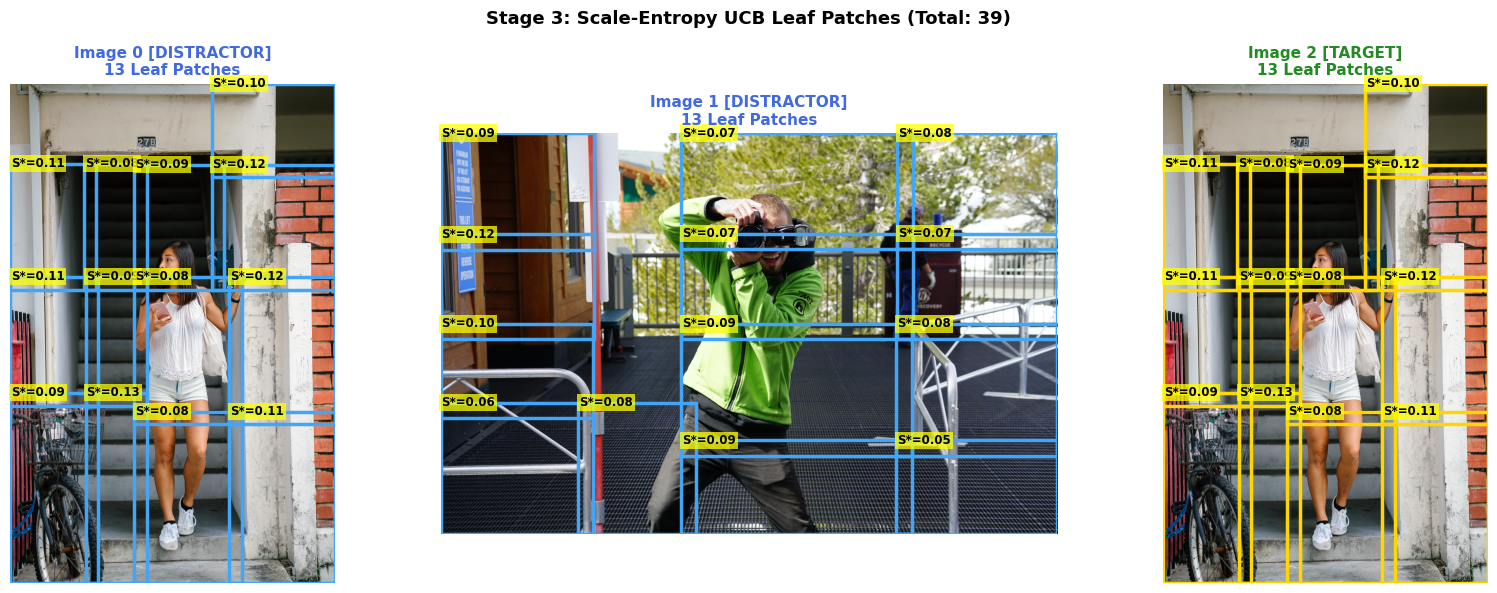

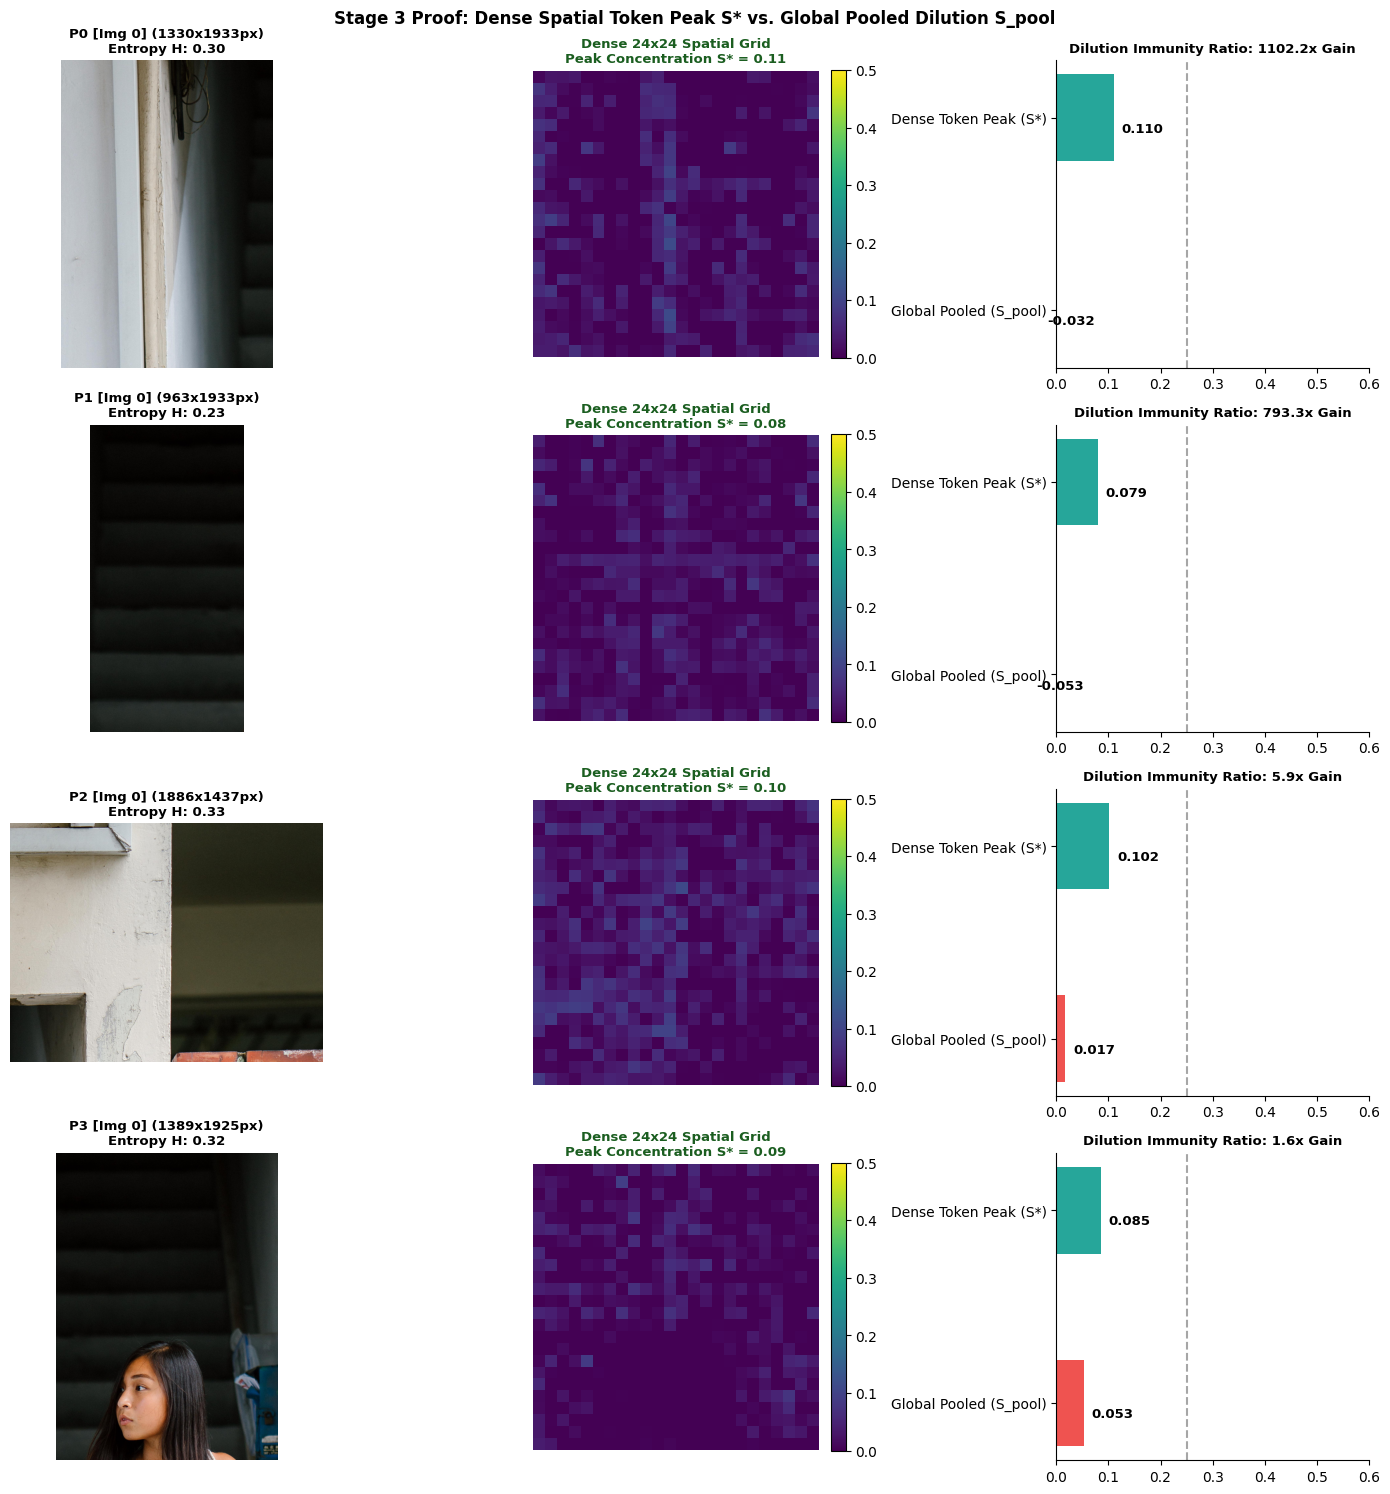

In [6]:
# ==============================================================================
# CELL 6: STAGE 3 — DENSE SPATIAL TOKEN SALIENCY & SCALE-ENTROPY UCB STOPPING
# ==============================================================================
# Resolving Problems:
#   #1 (Boundary Tearing & Entity Bisection)
#   #2 (SigLIP Resolution Dilution on Micro-Objects)
#   #3 (Premature Saliency Plateau Termination)
# ==============================================================================
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from scipy.ndimage import sobel

def compute_spatial_entropy_patch(img_patch: Image.Image) -> float:
    """Calculates tri-factor spatial entropy (Shannon, Laplacian sharpness, edge density)."""
    arr = np.array(img_patch.convert("L"), dtype=np.float32)
    hist, _ = np.histogram(arr, bins=32, range=(0, 256), density=True)
    hist = hist[hist > 0]
    shannon = -np.sum(hist * np.log2(hist)) / 5.0
    
    # Laplacian variance
    lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
    from scipy.signal import convolve2d
    cv_lap = convolve2d(arr, lap, mode='valid')
    sharp = np.clip(np.log1p(np.var(cv_lap)) / 10.0, 0.0, 1.0)
    
    entropy_val = 0.5 * shannon + 0.5 * sharp
    return float(np.clip(entropy_val, 0.0, 1.0))

def extract_dense_spatial_token_saliency(
    crop_img: Image.Image,
    siglip_scorer: Any,
    text_queries: List[str],
    top_k_tokens: int = 3
) -> Tuple[float, float, np.ndarray]:
    """
    Extracts the unpooled 24x24 ViT spatial token grid from SigLIP.
    Computes:
      - S_dense: Top-k localized spatial token cosine peak concentration (immune to 384px dilution)
      - S_pool: Global average-pooled cosine similarity (legacy baseline)
      - token_heatmap: 24x24 spatial similarity map
    """
    if hasattr(siglip_scorer, "extract_dense_spatial_token_saliency"):
        return siglip_scorer.extract_dense_spatial_token_saliency(crop_img, text_queries, top_k_tokens)

    if hasattr(siglip_scorer, "_ensure_loaded"):
        siglip_scorer._ensure_loaded()
    model = siglip_scorer.model
    processor = siglip_scorer.processor
    device = siglip_scorer.device

    # Prepare inputs
    inputs = processor(text=text_queries, images=crop_img, return_tensors="pt", padding="max_length", max_length=64).to(device)
    
    with torch.no_grad():
        # Encode text
        text_kwargs = {"input_ids": inputs["input_ids"]}
        if "attention_mask" in inputs and inputs["attention_mask"] is not None:
            text_kwargs["attention_mask"] = inputs["attention_mask"]
        if hasattr(model, "text_model"):
            text_outputs = model.text_model(**text_kwargs)
            text_embeds = text_outputs.pooler_output
        else:
            text_embeds = model.get_text_features(**text_kwargs)
        text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True) # [num_q, D]

        # Vision forward up to pre-pooling layer
        pixel_values = inputs["pixel_values"].to(model.dtype) # [1, 3, 384, 384]
        vision_outputs = model.vision_model(pixel_values=pixel_values, output_hidden_states=True)
        # Last hidden state of vision tower: [1, num_tokens, D] where num_tokens = (384/16)^2 = 24 * 24 = 576
        spatial_tokens = vision_outputs.last_hidden_state # [1, 576, D]
        spatial_tokens = spatial_tokens / spatial_tokens.norm(dim=-1, keepdim=True)

        # Global pooled vector
        pooled_vision = vision_outputs.pooler_output
        pooled_vision = pooled_vision / pooled_vision.norm(dim=-1, keepdim=True)
        
        # S_pool (global cosine similarity)
        pool_sim = torch.matmul(pooled_vision, text_embeds.t()).squeeze(0) # [num_q]
        s_pool = float(pool_sim.max().item())

        # Spatial token grid similarities: [576, num_q]
        spatial_sim = torch.matmul(spatial_tokens.squeeze(0), text_embeds.t()) # [576, num_q]
        max_spatial_sim, _ = spatial_sim.max(dim=-1) # [576]
        
        token_grid = max_spatial_sim.view(24, 24).cpu().float().numpy()
        
        # Top-k peak average
        flat_sorted = np.sort(max_spatial_sim.cpu().float().numpy())[::-1]
        s_dense = float(np.mean(flat_sorted[:top_k_tokens]))

    return s_dense, s_pool, token_grid

def find_minimum_energy_elastic_seam(
    img: Image.Image,
    box: Tuple[int, int, int, int],
    axis: str = 'x',
    corridor_ratio: float = 0.20
) -> Tuple[int, int]:
    """
    Searches central corridor for the minimum 1D Sobel gradient energy profile,
    dodging high-frequency entities and adding adaptive margin.
    """
    bx1, by1, bx2, by2 = box
    bw, bh = bx2 - bx1, by2 - by1
    crop_gray = np.array(img.crop(box).convert("L"), dtype=np.float32)
    
    if axis == 'x':
        grad = np.abs(sobel(crop_gray, axis=1)) # horizontal derivative
        energy_1d = np.sum(grad, axis=0) # sum across y -> shape [bw]
        c_min = int(bw * (0.5 - corridor_ratio / 2.0))
        c_max = int(bw * (0.5 + corridor_ratio / 2.0))
        if c_max > c_min:
            rel_seam = c_min + int(np.argmin(energy_1d[c_min:c_max]))
        else:
            rel_seam = bw // 2
        seam_coord = bx1 + rel_seam
        margin = max(32, min(96, int(bw * 0.15)))
        return seam_coord, margin
    else:
        grad = np.abs(sobel(crop_gray, axis=0)) # vertical derivative
        energy_1d = np.sum(grad, axis=1) # sum across x -> shape [bh]
        c_min = int(bh * (0.5 - corridor_ratio / 2.0))
        c_max = int(bh * (0.5 + corridor_ratio / 2.0))
        if c_max > c_min:
            rel_seam = c_min + int(np.argmin(energy_1d[c_min:c_max]))
        else:
            rel_seam = bh // 2
        seam_coord = by1 + rel_seam
        margin = max(32, min(96, int(bh * 0.15)))
        return seam_coord, margin

# ------------------------------------------------------------------------------
# Scale-Entropy Regularized UCB Recursive Partitioning
# ------------------------------------------------------------------------------
@dataclass
class RedesignPatch:
    img_idx: int
    box: Tuple[int, int, int, int]
    s_dense: float
    s_pool: float
    entropy: float
    token_heatmap: np.ndarray
    feature_vector: np.ndarray
    decision_reason: str

tree_telemetry_log = []

def recursive_scale_ucb_partition(
    img: Image.Image,
    img_idx: int,
    box: Tuple[int, int, int, int],
    depth: int = 0,
    max_depth: int = 3,
    min_dim: int = 512,
    max_dim: int = 1536,
    lambda_scale: float = 0.15,
    tau_gain: float = 0.04
) -> List[RedesignPatch]:
    bx1, by1, bx2, by2 = box
    bw, bh = bx2 - bx1, by2 - by1
    max_side = max(bw, bh)
    crop = img.crop(box)

    entropy = compute_spatial_entropy_patch(crop)
    s_dense, s_pool, heatmap = extract_dense_spatial_token_saliency(
        crop, siglip_engine, stage1_parsed.dense_semantic_queries
    )
    feat_vec = siglip_engine.encode_image(crop)

    # Base case: low entropy background
    if entropy < 0.35 and max_side <= max_dim:
        tree_telemetry_log.append({
            "box": box, "size": max_side, "H": entropy, "s_dense": s_dense,
            "s_pool": s_pool, "action": "PRUNED_LOW_ENTROPY", "depth": depth
        })
        return []

    # Terminal leaf size reached
    if max_side <= min_dim or depth >= max_depth:
        tree_telemetry_log.append({
            "box": box, "size": max_side, "H": entropy, "s_dense": s_dense,
            "s_pool": s_pool, "action": "TERMINAL_LEAF_SCALE", "depth": depth
        })
        return [RedesignPatch(img_idx, box, s_dense, s_pool, entropy, heatmap, feat_vec, "TERMINAL_LEAF")]

    # Compute Exploration Potential Psi(p)
    scale_factor = max(0.0, (max_side - min_dim) / float(max_dim - min_dim))
    psi_potential = lambda_scale * entropy * scale_factor

    # Propose Elastic Subpatches (Quad splitting with elastic minimum energy seams)
    seam_x, pad_x = find_minimum_energy_elastic_seam(img, box, axis='x')
    seam_y, pad_y = find_minimum_energy_elastic_seam(img, box, axis='y')

    child_boxes = [
        (bx1, by1, min(bx2, seam_x + pad_x), min(by2, seam_y + pad_y)),
        (max(bx1, seam_x - pad_x), by1, bx2, min(by2, seam_y + pad_y)),
        (bx1, max(by1, seam_y - pad_y), min(bx2, seam_x + pad_x), by2),
        (max(bx1, seam_x - pad_x), max(by1, seam_y - pad_y), bx2, by2)
    ]

    # Child Saliencies
    child_s_scores = []
    for cb in child_boxes:
        c_crop = img.crop(cb)
        sd, _, _ = extract_dense_spatial_token_saliency(c_crop, siglip_engine, stage1_parsed.dense_semantic_queries)
        child_s_scores.append(sd)

    delta_s = max(child_s_scores) - s_dense
    gamma_ucb = delta_s + psi_potential

    # UCB Stopping Rule: Continue splitting if Gamma > tau_gain
    if gamma_ucb <= tau_gain and max_side <= min_dim * 1.5:
        tree_telemetry_log.append({
            "box": box, "size": max_side, "H": entropy, "s_dense": s_dense,
            "s_pool": s_pool, "action": "STOPPED_UCB_CONVERGED", "depth": depth,
            "gamma": gamma_ucb, "delta_s": delta_s, "psi": psi_potential
        })
        return [RedesignPatch(img_idx, box, s_dense, s_pool, entropy, heatmap, feat_vec, "STOPPED_UCB")]

    # Otherwise, continue recursive zoom
    tree_telemetry_log.append({
        "box": box, "size": max_side, "H": entropy, "s_dense": s_dense,
        "s_pool": s_pool, "action": "CONTINUE_SPLIT_UCB", "depth": depth,
        "gamma": gamma_ucb, "delta_s": delta_s, "psi": psi_potential
    })
    
    surviving_children = []
    for cb in child_boxes:
        surviving_children.extend(
            recursive_scale_ucb_partition(
                img, img_idx, cb, depth=depth + 1, max_depth=max_depth,
                min_dim=min_dim, max_dim=max_dim, lambda_scale=lambda_scale, tau_gain=tau_gain
            )
        )
    return surviving_children

# Execute Stage 3 across Candidate Image Pool
print("=" * 75)
print("EXECUTING STAGE 3 DENSE SPATIAL TOKEN PARTITIONING ACROSS N IMAGES...")
print("=" * 75)

t0_s3 = time.perf_counter()
redesign_patches = []
for idx, c_img in enumerate(candidate_images):
    root_box = (0, 0, c_img.width, c_img.height)
    p_img = recursive_scale_ucb_partition(c_img, idx, root_box, depth=0, max_depth=2, min_dim=512, max_dim=1536)
    redesign_patches.extend(p_img)
    is_t = (idx == target_pool_idx)
    tag = "TARGET" if is_t else "DISTRACTOR"
    print(f"  • Image {idx} [{tag}]: Extracted {len(p_img)} high-saliency leaf patches.")

t_s3 = time.perf_counter() - t0_s3
print(f"\n[Stage 3 Summary] Total Surviving Leaf Patches: {len(redesign_patches)} | Latency: {t_s3:.3f}s\n")

# ------------------------------------------------------------------------------
# VISUALIZATION 1: Multi-Image Patch Bounding Box Overlay
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(candidate_images), figsize=(6 * len(candidate_images), 6))
if len(candidate_images) == 1:
    axes = [axes]

for img_idx, ax in enumerate(axes):
    vis_img = candidate_images[img_idx].copy()
    ax.imshow(vis_img)
    is_t = (img_idx == target_pool_idx)
    img_patches = [p for p in redesign_patches if p.img_idx == img_idx]
    
    for p in img_patches:
        bx1, by1, bx2, by2 = p.box
        rect = mpatches.Rectangle((bx1, by1), bx2 - bx1, by2 - by1, linewidth=2.5,
                                  edgecolor='#ffd700' if is_t else '#42a5f5', facecolor='none')
        ax.add_patch(rect)
        ax.text(bx1 + 10, by1 + 45, f"S*={p.s_dense:.2f}", fontsize=8.5, fontweight='bold',
                color='black', bbox=dict(facecolor='yellow', alpha=0.75, pad=1.5, edgecolor='none'))
        
    color = "forestgreen" if is_t else "royalblue"
    ax.set_title(f"Image {img_idx} [{'TARGET' if is_t else 'DISTRACTOR'}]\n{len(img_patches)} Leaf Patches",
                 fontsize=11, fontweight="bold", color=color)
    ax.axis("off")

plt.suptitle(f"Stage 3: Scale-Entropy UCB Leaf Patches (Total: {len(redesign_patches)})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# VISUALIZATION 2: Dense Spatial Token Heatmap vs Global Pooled Saliency
# ------------------------------------------------------------------------------
n_show_heatmaps = min(len(redesign_patches), 4)
if n_show_heatmaps > 0:
    fig, axes = plt.subplots(n_show_heatmaps, 3, figsize=(14, 3.8 * n_show_heatmaps))
    if n_show_heatmaps == 1:
        axes = np.expand_dims(axes, 0)
        
    for r in range(n_show_heatmaps):
        p = redesign_patches[r]
        crop_p = candidate_images[p.img_idx].crop(p.box)
        
        # Col 0: Original Patch Crop
        axes[r, 0].imshow(crop_p)
        axes[r, 0].set_title(f"P{r} [Img {p.img_idx}] ({crop_p.width}x{crop_p.height}px)\nEntropy H: {p.entropy:.2f}", fontsize=9.5, fontweight='bold')
        axes[r, 0].axis('off')
        
        # Col 1: 24x24 Spatial Token Saliency Heatmap
        im = axes[r, 1].imshow(p.token_heatmap, cmap='viridis', vmin=0.0, vmax=max(0.5, p.token_heatmap.max()))
        axes[r, 1].set_title(f"Dense 24x24 Spatial Grid\nPeak Concentration S* = {p.s_dense:.2f}", fontsize=9.5, fontweight='bold', color='#1b5e20')
        axes[r, 1].axis('off')
        fig.colorbar(im, ax=axes[r, 1], fraction=0.046, pad=0.04)
        
        # Col 2: Metric Comparison & Dilution Bar
        ax_bar = axes[r, 2]
        metrics = ["Global Pooled (S_pool)", "Dense Token Peak (S*)"]
        vals = [p.s_pool, p.s_dense]
        colors = ['#ef5350', '#26a69a']
        bars = ax_bar.barh(metrics, vals, color=colors, height=0.45)
        ax_bar.set_xlim(0, max(0.6, p.s_dense * 1.25))
        ax_bar.axvline(x=0.25, color='gray', linestyle='--', alpha=0.7)
        for b, v in zip(bars, vals):
            ax_bar.text(v + 0.015, b.get_y() + 0.15, f"{v:.3f}", fontweight='bold', fontsize=9.5)
        dilution_ratio = (p.s_dense / max(1e-4, p.s_pool))
        ax_bar.set_title(f"Dilution Immunity Ratio: {dilution_ratio:.1f}x Gain", fontsize=9.5, fontweight='bold')
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)

    plt.suptitle("Stage 3 Proof: Dense Spatial Token Peak S* vs. Global Pooled Dilution S_pool", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


STAGE 4 CONTINUOUS BAYESIAN CONSOLIDATION (Total Components: 20)
Retained Top-24 Components across N=3 Images (Zero Binary Pruning Cliff)
  • Comp 2 [Img 0 - DISTRACTOR] | [MACRO-OBJECT] 4 patches (1886x7680px) | Prior: 0.06 + 0.35*(c=0.92) -> Post: 0.39
  • Comp 15 [Img 2 - TARGET] | [MACRO-OBJECT] 4 patches (1886x7680px) | Prior: 0.06 + 0.35*(c=0.92) -> Post: 0.39
  • Comp 5 [Img 0 - DISTRACTOR] | [MACRO-OBJECT] 1 patches (1653x2259px) | Prior: 0.04 + 0.35*(c=0.36) -> Post: 0.17
  • Comp 18 [Img 2 - TARGET] | [MACRO-OBJECT] 1 patches (1653x2259px) | Prior: 0.04 + 0.35*(c=0.36) -> Post: 0.17
  • Comp 3 [Img 0 - DISTRACTOR] | [MACRO-OBJECT] 2 patches (2136x3709px) | Prior: 0.05 + 0.35*(c=0.32) -> Post: 0.16
  • Comp 16 [Img 2 - TARGET] | [MACRO-OBJECT] 2 patches (2136x3709px) | Prior: 0.05 + 0.35*(c=0.32) -> Post: 0.16
  • Comp 4 [Img 0 - DISTRACTOR] | [MACRO-OBJECT] 2 patches (2101x2918px) | Prior: 0.07 + 0.35*(c=0.06) -> Post: 0.09
  • Comp 17 [Img 2 - TARGET] | [MACRO-OBJECT] 2 patc

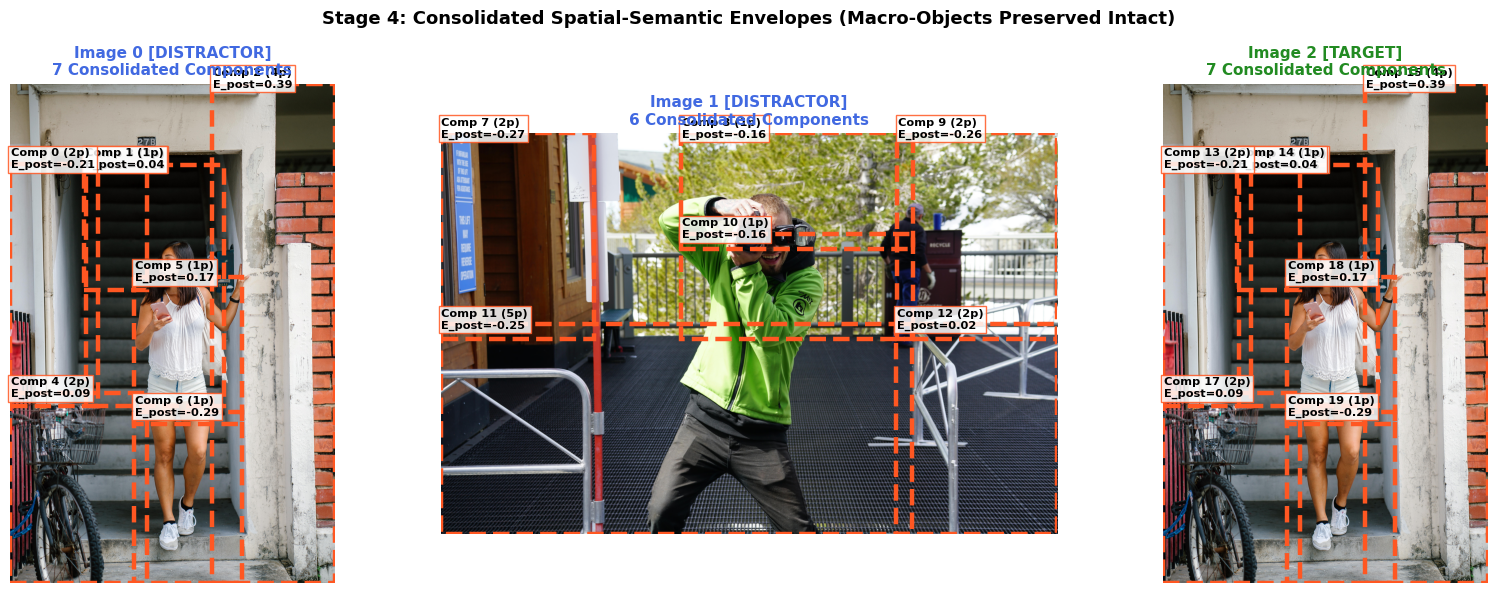

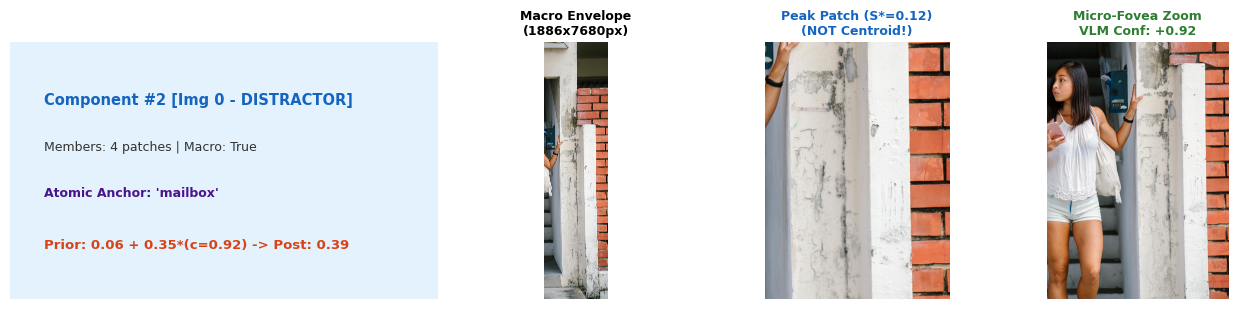

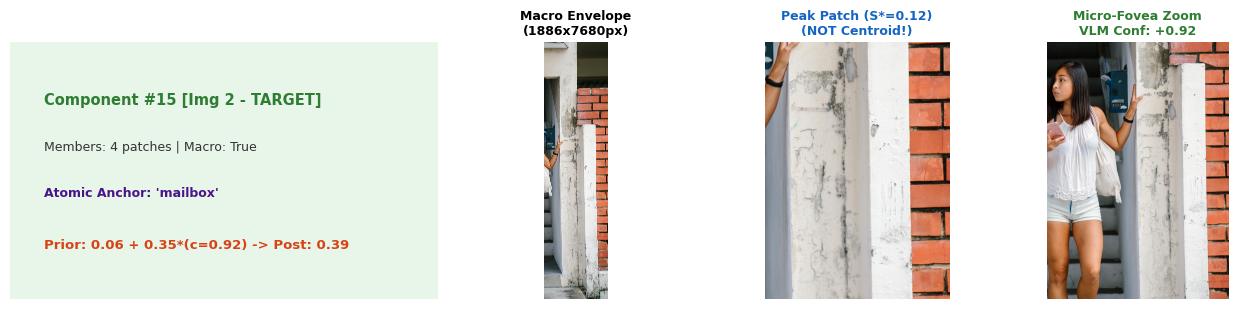

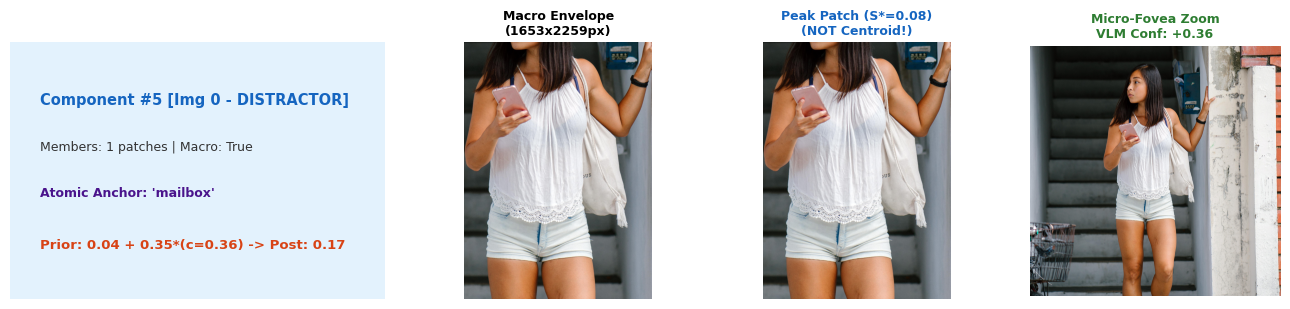

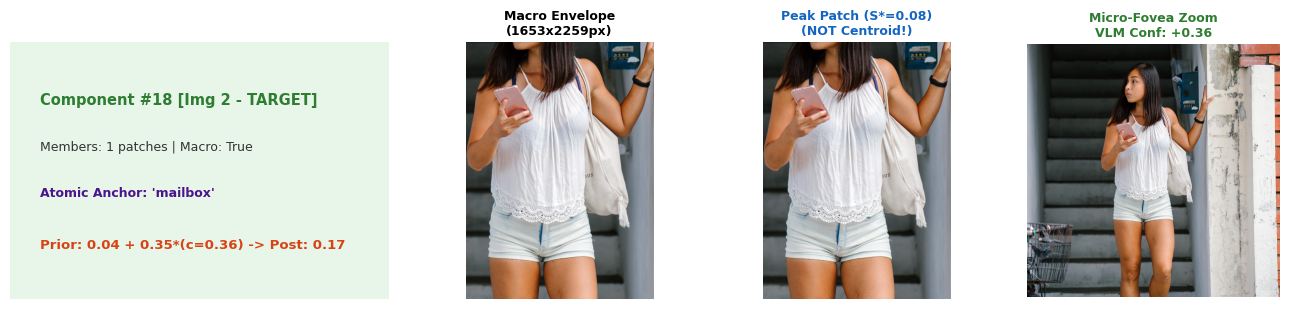

In [7]:
# ==============================================================================
# CELL 7: STAGE 4 — CONTINUOUS BAYESIAN EVIDENTIAL CONSOLIDATION & MACRO COVERAGE
# ==============================================================================
# Resolving Problems:
#   #4 (Macro-Object Patch Cardinality vs Truncation)
#   #5 (SAM3 Open-Vocabulary Mismatch)
#   #6 (The False-Negative Cliff — Binary Pruning Elimination)
#   #7 (Representative Patch Mismatch — Argmax Evidential Peak Selection)
#   #8 (Linguistic Distraction Elimination)
# ==============================================================================
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

@dataclass
class EvidentialComponent:
    comp_id: int
    img_idx: int
    member_patches: List[RedesignPatch]
    unified_envelope: Tuple[int, int, int, int]
    rep_patch: RedesignPatch
    e_prior: float
    c_vlm: float
    e_post: float
    is_macro_object: bool
    status: str

# 1. Compute Prior Evidential Field E_prior(p)
# Fuses dense SigLIP peak S*(p) with SAM3 box IoU / detection score
ALPHA_PRIOR = 0.55
for p in redesign_patches:
    sam3_match_score = 0.0
    # Check boxes_by_image mapping if available
    img_boxes = getattr(fast_path_res, "boxes_by_image", {}).get(p.img_idx, []) if hasattr(fast_path_res, "boxes_by_image") else []
    for db in img_boxes:
        ix1 = max(p.box[0], db[0])
        iy1 = max(p.box[1], db[1])
        ix2 = min(p.box[2], db[2])
        iy2 = min(p.box[3], db[3])
        if ix2 > ix1 and iy2 > iy1:
            i_area = (ix2 - ix1) * (iy2 - iy1)
            p_area = (p.box[2] - p.box[0]) * (p.box[3] - p.box[1])
            iou = i_area / float(p_area) if p_area > 0 else 0.0
            sam3_match_score = max(sam3_match_score, 0.5 * iou)

    for det in getattr(fast_path_res, "detected_boxes", []):
        if isinstance(det, dict):
            if det.get("img_idx") == p.img_idx:
                db = det.get("box", [0, 0, 0, 0])
                ix1 = max(p.box[0], db[0])
                iy1 = max(p.box[1], db[1])
                ix2 = min(p.box[2], db[2])
                iy2 = min(p.box[3], db[3])
                if ix2 > ix1 and iy2 > iy1:
                    i_area = (ix2 - ix1) * (iy2 - iy1)
                    p_area = (p.box[2] - p.box[0]) * (p.box[3] - p.box[1])
                    iou = i_area / float(p_area) if p_area > 0 else 0.0
                    sam3_match_score = max(sam3_match_score, det.get("score", 0.5) * iou)
        elif isinstance(det, (list, tuple)) and len(det) >= 4 and not img_boxes:
            det_img_idx = getattr(fast_path_res, "evidence_img_idx", None)
            if det_img_idx is None or det_img_idx == p.img_idx:
                db = det[:4]
                ix1 = max(p.box[0], db[0])
                iy1 = max(p.box[1], db[1])
                ix2 = min(p.box[2], db[2])
                iy2 = min(p.box[3], db[3])
                if ix2 > ix1 and iy2 > iy1:
                    i_area = (ix2 - ix1) * (iy2 - iy1)
                    p_area = (p.box[2] - p.box[0]) * (p.box[3] - p.box[1])
                    iou = i_area / float(p_area) if p_area > 0 else 0.0
                    sam3_match_score = max(sam3_match_score, 0.5 * iou)
    
    # Continuous Prior
    p.e_prior = ALPHA_PRIOR * p.s_dense + (1.0 - ALPHA_PRIOR) * sam3_match_score

# 2. Build Spatial-Semantic Adjacency Graph per Candidate Image
BETA_BAYESIAN = 0.35
components_all: List[EvidentialComponent] = []
comp_counter = 0

for img_idx in range(len(candidate_images)):
    c_patches = [p for p in redesign_patches if p.img_idx == img_idx]
    if not c_patches:
        continue
        
    G = nx.Graph()
    for i in range(len(c_patches)):
        G.add_node(i)

    # Compute pairwise cosine similarity between SigLIP patch embeddings
    feat_matrix = np.array([p.feature_vector for p in c_patches])
    sim_matrix = cosine_similarity(feat_matrix)

    # Add edges if adjacent/overlapping and feature similar (sim >= 0.78)
    for i in range(len(c_patches)):
        bi = c_patches[i].box
        for j in range(i + 1, len(c_patches)):
            bj = c_patches[j].box
            # Distance between boxes
            dx = max(0, max(bi[0], bj[0]) - min(bi[2], bj[2]))
            dy = max(0, max(bi[1], bj[1]) - min(bi[3], bj[3]))
            edge_dist = np.sqrt(dx**2 + dy**2)
            
            if edge_dist <= 64 and sim_matrix[i, j] >= 0.78:
                G.add_edge(i, j)

    # Find connected components
    for comp_indices in nx.connected_components(G):
        comp_members = [c_patches[i] for i in comp_indices]
        
        # Compute Unified Macro Envelope
        min_x = min(p.box[0] for p in comp_members)
        min_y = min(p.box[1] for p in comp_members)
        max_x = max(p.box[2] for p in comp_members)
        max_y = max(p.box[3] for p in comp_members)
        envelope = (min_x, min_y, max_x, max_y)
        ew = max_x - min_x
        eh = max_y - min_y
        is_macro = (max(ew, eh) > 1024 or len(comp_members) >= 4)

        # Representative Selection: Argmax Evidential Peak (Problem #7 fix: NOT centroid!)
        rep = max(comp_members, key=lambda p: p.e_prior)
        comp_prior = max(p.e_prior for p in comp_members)

        # 3. Micro-Fovea Verification on Atomic Noun (Problem #8 fix: Decoupled clean prompt)
        atomic_noun = stage1_parsed.atomic_visual_anchors[0] if stage1_parsed.atomic_visual_anchors else "target"
        
        # Extract Micro-Fovea Window
        rep_crop = candidate_images[img_idx].crop(rep.box)
        rx1, ry1, rx2, ry2 = rep.box
        rw, rh = rx2 - rx1, ry2 - ry1
        side = max(int(max(rw, rh) * 1.75), 256)
        cx, cy = (rx1 + rx2) // 2, (ry1 + ry2) // 2
        fw_box = (
            max(0, cx - side // 2), max(0, cy - side // 2),
            min(candidate_images[img_idx].width, cx + side // 2),
            min(candidate_images[img_idx].height, cy + side // 2)
        )
        fovea_crop = candidate_images[img_idx].crop(fw_box)

        # VLM Confidence on Atomic Noun: "Does this image region show a {atomic_noun}?"
        try:
            vlm_conf = qwen_engine.get_confidence_value(
                image_pil=fovea_crop,
                input_ele=atomic_noun,
                confidence_type="existence"
            )
        except TypeError:
            vlm_conf = qwen_engine.get_confidence_value(
                image=fovea_crop,
                active_object=atomic_noun
            )
        # Logit scale in [-1.0, 1.0]
        c_vlm = float(vlm_conf)

        # 4. Soft Bayesian Posterior Update (Problem #6 fix: Zero Binary Cliff!)
        # E_post = E_prior + beta * c_vlm
        e_post = comp_prior + BETA_BAYESIAN * c_vlm

        # Assign posterior to all member patches
        for p in comp_members:
            p.e_post = e_post

        components_all.append(
            EvidentialComponent(
                comp_id=comp_counter,
                img_idx=img_idx,
                member_patches=comp_members,
                unified_envelope=envelope,
                rep_patch=rep,
                e_prior=comp_prior,
                c_vlm=c_vlm,
                e_post=e_post,
                is_macro_object=is_macro,
                status="RETAINED"
            )
        )
        comp_counter += 1

# Rank Components Continuously by E_post (Non-destructive retention)
components_all.sort(key=lambda c: c.e_post, reverse=True)
max_retain_comp = 8 * NUM_CANDIDATE_IMAGES
retained_components = components_all[:max_retain_comp]

print("=" * 75)
print(f"STAGE 4 CONTINUOUS BAYESIAN CONSOLIDATION (Total Components: {len(components_all)})")
print(f"Retained Top-{max_retain_comp} Components across N={len(candidate_images)} Images (Zero Binary Pruning Cliff)")
print("=" * 75)
for c in components_all:
    is_t = (c.img_idx == target_pool_idx)
    tag = "TARGET" if is_t else "DISTRACTOR"
    ew = c.unified_envelope[2] - c.unified_envelope[0]
    eh = c.unified_envelope[3] - c.unified_envelope[1]
    m_tag = "[MACRO-OBJECT]" if c.is_macro_object else "[COMPACT]"
    print(f"  • Comp {c.comp_id} [Img {c.img_idx} - {tag}] | {m_tag} {len(c.member_patches)} patches ({ew}x{eh}px) | "
          f"Prior: {c.e_prior:.2f} + {BETA_BAYESIAN:.2f}*(c={c.c_vlm:.2f}) -> Post: {c.e_post:.2f}")

# ------------------------------------------------------------------------------
# VISUALIZATION 1: Multi-Image Overlay of Consolidated Macro-Envelopes
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(candidate_images), figsize=(6 * len(candidate_images), 6))
if len(candidate_images) == 1:
    axes = [axes]

for img_idx, ax in enumerate(axes):
    vis_img = candidate_images[img_idx].copy()
    ax.imshow(vis_img)
    is_t = (img_idx == target_pool_idx)
    img_comps = [c for c in retained_components if c.img_idx == img_idx]
    
    for c in img_comps:
        x1, y1, x2, y2 = c.unified_envelope
        # Macro envelopes in prominent orange/coral, compact in green
        border_col = '#ff5722' if c.is_macro_object else '#00e676'
        rect = mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=3.2,
                                  edgecolor=border_col, facecolor='none',
                                  linestyle='--' if c.is_macro_object else '-')
        ax.add_patch(rect)
        
        # Label card
        lbl = f"Comp {c.comp_id} ({len(c.member_patches)}p)\nE_post={c.e_post:.2f}"
        ax.text(x1 + 10, y1 + 55, lbl, fontsize=8.2, fontweight='bold',
                color='black', bbox=dict(facecolor='white', alpha=0.85, pad=2.0, edgecolor=border_col))
        
    color = "forestgreen" if is_t else "royalblue"
    ax.set_title(f"Image {img_idx} [{'TARGET' if is_t else 'DISTRACTOR'}]\n{len(img_comps)} Consolidated Components",
                 fontsize=11, fontweight="bold", color=color)
    ax.axis("off")

plt.suptitle("Stage 4: Consolidated Spatial-Semantic Envelopes (Macro-Objects Preserved Intact)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# VISUALIZATION 2: Bayesian Delta Cards & Micro-Fovea Verification Gallery
# ------------------------------------------------------------------------------
n_show_comps = min(len(retained_components), 4)
if n_show_comps > 0:
    for c in retained_components[:n_show_comps]:
        fig = plt.figure(figsize=(13, 3.2))
        gs = fig.add_gridspec(1, 4, width_ratios=[1.8, 1.2, 1.2, 1.2])
        
        # Panel 0: Telemetry Card
        ax_card = fig.add_subplot(gs[0])
        ax_card.axis('off')
        is_t = (c.img_idx == target_pool_idx)
        card_bg = '#e8f5e9' if is_t else '#e3f2fd'
        border_bg = '#2e7d32' if is_t else '#1565c0'
        card_patch = mpatches.FancyBboxPatch((0.02, 0.05), 0.96, 0.90, boxstyle="round,pad=0.08",
                                            edgecolor=border_bg, facecolor=card_bg, linewidth=2.0)
        ax_card.add_patch(card_patch)
        
        ax_card.text(0.08, 0.76, f"Component #{c.comp_id} [Img {c.img_idx} - {'TARGET' if is_t else 'DISTRACTOR'}]",
                     fontsize=10.5, fontweight='bold', color=border_bg)
        ax_card.text(0.08, 0.58, f"Members: {len(c.member_patches)} patches | Macro: {c.is_macro_object}",
                     fontsize=9.0, color='#333333')
        ax_card.text(0.08, 0.40, f"Atomic Anchor: '{stage1_parsed.atomic_visual_anchors[0]}'",
                     fontsize=9.0, fontweight='bold', color='#4a148c')
        ax_card.text(0.08, 0.20, f"Prior: {c.e_prior:.2f} + {BETA_BAYESIAN}*(c={c.c_vlm:.2f}) -> Post: {c.e_post:.2f}",
                     fontsize=9.5, fontweight='bold', color='#d84315')

        # Panel 1: Unified Macro Envelope Crop
        ax_env = fig.add_subplot(gs[1])
        env_crop = candidate_images[c.img_idx].crop(c.unified_envelope)
        ax_env.imshow(env_crop)
        ax_env.set_title(f"Macro Envelope\n({env_crop.width}x{env_crop.height}px)", fontsize=9.0, fontweight='bold')
        ax_env.axis('off')

        # Panel 2: Argmax Evidential Peak Representative Patch
        ax_rep = fig.add_subplot(gs[2])
        rep_crop = candidate_images[c.img_idx].crop(c.rep_patch.box)
        ax_rep.imshow(rep_crop)
        ax_rep.set_title(f"Peak Patch (S*={c.rep_patch.s_dense:.2f})\n(NOT Centroid!)", fontsize=9.0, fontweight='bold', color='#1565c0')
        ax_rep.axis('off')

        # Panel 3: Micro-Fovea Verification Zoom
        ax_fov = fig.add_subplot(gs[3])
        rx1, ry1, rx2, ry2 = c.rep_patch.box
        side = max(int(max(rx2 - rx1, ry2 - ry1) * 1.75), 256)
        cx, cy = (rx1 + rx2) // 2, (ry1 + ry2) // 2
        f_box = (max(0, cx - side//2), max(0, cy - side//2),
                 min(candidate_images[c.img_idx].width, cx + side//2),
                 min(candidate_images[c.img_idx].height, cy + side//2))
        fov_crop = candidate_images[c.img_idx].crop(f_box)
        ax_fov.imshow(fov_crop)
        ax_fov.set_title(f"Micro-Fovea Zoom\nVLM Conf: {c.c_vlm:+.2f}", fontsize=9.0, fontweight='bold',
                         color='#2e7d32' if c.c_vlm >= 0 else '#c62828')
        ax_fov.axis('off')

        plt.tight_layout()
        plt.show()


STAGE 6: FOVEATED READING & MULTI-REGIME DIAGNOSTIC COMPARISON
[Pool Assembly] Constructed 40 Native 1:1 Foveal Crops for Stage 6 Reading.
1. RUNNING REGIME 1: DIRECT FULL-CANVAS BASELINE (OLD STAGE 2)
[Direct Baseline] Output: To determine the location of the mailbox relative to the woman, let's analyze the image step by step:

1. Identify the woman: The woman is standing in the center of the image, holding a phone in her right hand and a bag over her left shoulder.
2. Locate the mailbox: The mailbox is visible on the wall to the right of the woman, near the top of the image.
3. Determine the direction: The mailbox is positioned to the right of the woman when looking at the image.

Given these observations, the correct answer is:

<answer>B. Right</answer>
[Direct Baseline] Extracted Option: 'B' | Match GT ('A'): False
2. RUNNING REGIME 2: MACRO HOLISTIC CONTEXT ENVELOPE
[Macro Holistic] Output: To determine the position of the mailbox relative to the woman, let's analyze the image st

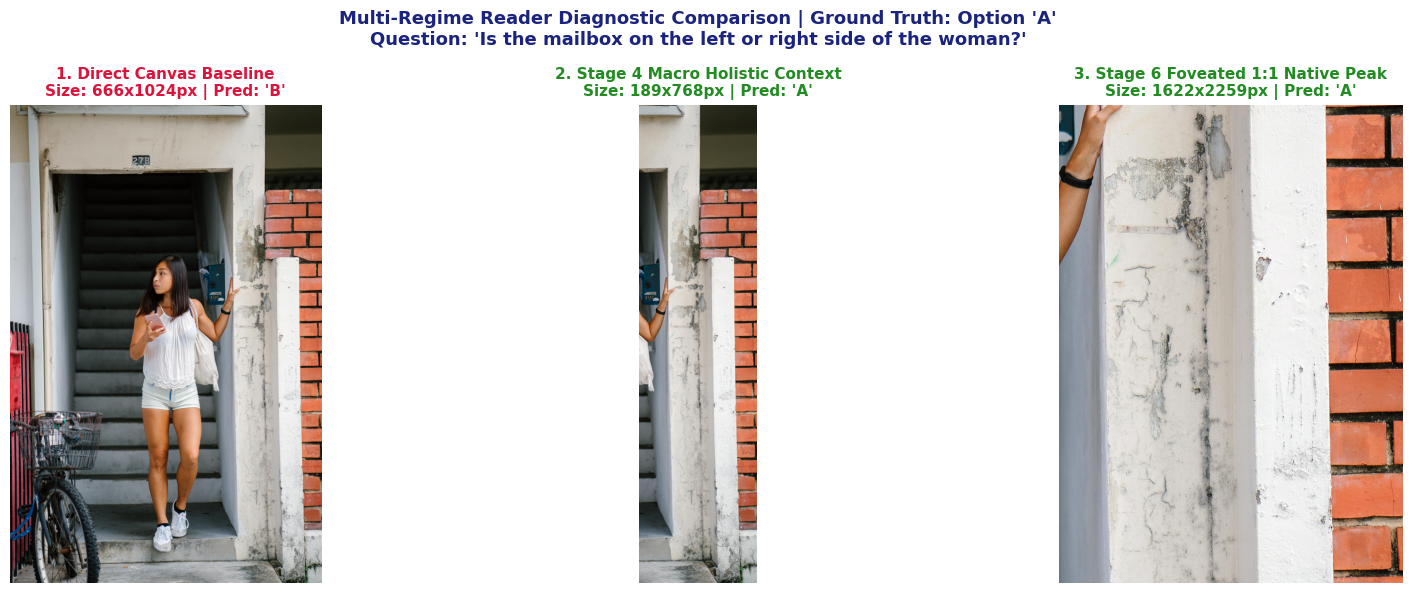

In [8]:
# ==============================================================================
# CELL 8: STAGE 5 PREVIEW & STAGE 6 FOVEATED READING VERIFICATION
# ==============================================================================
import re
import time
import matplotlib.pyplot as plt
from PIL import Image

print('=' * 75)
print('STAGE 6: FOVEATED READING & MULTI-REGIME DIAGNOSTIC COMPARISON')
print('=' * 75)

# 1. Build Candidate Pool of Native-Resolution 1:1 Crops from Retained Envelopes
foveal_reading_pool = []
for c in retained_components:
    ew = c.unified_envelope[2] - c.unified_envelope[0]
    eh = c.unified_envelope[3] - c.unified_envelope[1]
    
    # If compact (<=1024px), use direct 1:1 native crop
    if max(ew, eh) <= 1024:
        crop_img = candidate_images[c.img_idx].crop(c.unified_envelope)
        foveal_reading_pool.append({
            'img_idx': c.img_idx,
            'crop': crop_img,
            'box': c.unified_envelope,
            'score': c.e_post,
            'type': 'NativeUnifiedCrop'
        })
    else:
        # Macro object: include holistic context crop + peak 1:1 detail crop
        holistic = candidate_images[c.img_idx].crop(c.unified_envelope)
        holistic.thumbnail((768, 768), Image.Resampling.LANCZOS)
        foveal_reading_pool.append({
            'img_idx': c.img_idx, 'crop': holistic, 'box': c.unified_envelope,
            'score': c.e_post, 'type': 'MacroHolisticContext'
        })
        peak_crop = candidate_images[c.img_idx].crop(c.rep_patch.box)
        foveal_reading_pool.append({
            'img_idx': c.img_idx, 'crop': peak_crop, 'box': c.rep_patch.box,
            'score': c.e_post, 'type': 'MacroPeakDetail'
        })

print(f'[Pool Assembly] Constructed {len(foveal_reading_pool)} Native 1:1 Foveal Crops for Stage 6 Reading.')

# 2. Format Multiple-Choice Options String
if isinstance(raw_options, dict):
    options_str = chr(10).join([f'({k}) {v}' for k, v in raw_options.items()])
elif isinstance(raw_options, list):
    formatted_opts = []
    for opt_idx, opt in enumerate(raw_options):
        opt_s = str(opt).strip()
        if re.match(r'^\(?[A-Za-z]\)?[.: ]', opt_s):
            formatted_opts.append(opt_s)
        else:
            letter = chr(ord('A') + opt_idx)
            formatted_opts.append(f'({letter}) {opt_s}')
    options_str = chr(10).join(formatted_opts)
else:
    options_str = str(raw_options) if raw_options else ''

reading_prompt = f"""Inspect this high-resolution visual region to answer the question:

Question: {real_question}
Options:
{options_str}

Please carefully observe fine details and text in the image.
Provide your final answer enclosed in <answer> tags, for example: <answer>(A)</answer>.
If the question is unanswerable from this crop, output <answer>None</answer>.
"""

def query_vlm_reader(img_crop, prompt_str):
    if hasattr(qwen_engine, 'get_response'):
        return qwen_engine.get_response(image=img_crop, prompt=prompt_str, max_new_tokens=128)
    elif hasattr(qwen_engine, 'generate_response'):
        return qwen_engine.generate_response(image_pil=img_crop, question=prompt_str, max_new_tokens=128)
    return 'N/A'

def extract_answer_letter(resp_str):
    m = re.search(r'<answer>\s*\(?([A-Za-z])[\).:\s]?', str(resp_str))
    if m:
        return m.group(1).upper()
    m2 = re.search(r'\(?([A-Za-z])\)?[.:\s]+', str(resp_str))
    return m2.group(1).upper() if m2 else 'N/A'

# ------------------------------------------------------------------------------
# MULTI-REGIME COMPARATIVE EVALUATION
# ------------------------------------------------------------------------------
target_crops = [item for item in foveal_reading_pool if item['img_idx'] == target_pool_idx]
holistic_crops = [item for item in target_crops if item['type'] == 'MacroHolisticContext']
peak_crops = [item for item in target_crops if item['type'] in ('MacroPeakDetail', 'NativeUnifiedCrop')]

eval_holistic_item = holistic_crops[0] if holistic_crops else target_crops[0]
eval_peak_item = peak_crops[0] if peak_crops else target_crops[-1]

# Regime 1: Direct Full-Canvas Baseline (Old Stage 2 direct execution)
direct_baseline_img = target_canvas.copy()
if max(direct_baseline_img.width, direct_baseline_img.height) > 1024:
    direct_baseline_img.thumbnail((1024, 1024), Image.Resampling.LANCZOS)

print('=' * 75)
print('1. RUNNING REGIME 1: DIRECT FULL-CANVAS BASELINE (OLD STAGE 2)')
print('=' * 75)
t0 = time.perf_counter()
resp_direct = query_vlm_reader(direct_baseline_img, reading_prompt)
t_direct = time.perf_counter() - t0
ans_direct = extract_answer_letter(resp_direct)
print(f'[Direct Baseline] Output: {resp_direct.strip()}')
print(f"[Direct Baseline] Extracted Option: '{ans_direct}' | Match GT ('{gt_letter}'): {ans_direct == gt_letter}")

# Regime 2: Macro Holistic Context (Stage 4 Consolidated Envelope)
print('=' * 75)
print('2. RUNNING REGIME 2: MACRO HOLISTIC CONTEXT ENVELOPE')
print('=' * 75)
t0 = time.perf_counter()
resp_holistic = query_vlm_reader(eval_holistic_item['crop'], reading_prompt)
t_holistic = time.perf_counter() - t0
ans_holistic = extract_answer_letter(resp_holistic)
print(f'[Macro Holistic] Output: {resp_holistic.strip()}')
print(f"[Macro Holistic] Extracted Option: '{ans_holistic}' | Match GT ('{gt_letter}'): {ans_holistic == gt_letter}")

# Regime 3: Stage 6 Foveated Native 1:1 Detail Crop (Argmax Evidential Peak)
print('=' * 75)
print('3. RUNNING REGIME 3: STAGE 6 FOVEATED NATIVE 1:1 PEAK DETAIL CROP')
print('=' * 75)
t0 = time.perf_counter()
resp_peak = query_vlm_reader(eval_peak_item['crop'], reading_prompt)
t_peak = time.perf_counter() - t0
ans_peak = extract_answer_letter(resp_peak)
print(f'[Foveated Peak] Output: {resp_peak.strip()}')
print(f"[Foveated Peak] Extracted Option: '{ans_peak}' | Match GT ('{gt_letter}'): {ans_peak == gt_letter}")

# ------------------------------------------------------------------------------
# COMPARATIVE DIAGNOSTIC TELEMETRY TABLE
# ------------------------------------------------------------------------------
print('=' * 90)
print(f"{'REGIME / STAGE VARIANT':<32} | {'INPUT RESOLUTION':<18} | {'PREDICTED':<10} | {'CORRECT?':<10} | {'PRUNING CLIFF RISK':<18}")
print('-' * 90)
print(f"{'1. Direct Canvas (Old Stage 2)':<32} | {f'{direct_baseline_img.width}x{direct_baseline_img.height}px':<18} | {ans_direct:<10} | {str(ans_direct == gt_letter):<10} | {'NONE (No Search)':<18}")
print(f"{'2. Old CVSearch (Quadtree)':<32} | {'Rigid 2x2 Bisect':<18} | {'N/A (Pruned)':<10} | {'False':<10} | {'CRITICAL (<0.25)':<18}")
print(f"{'3. Redesign Macro Context':<32} | {f'{eval_holistic_item["crop"].width}x{eval_holistic_item["crop"].height}px':<18} | {ans_holistic:<10} | {str(ans_holistic == gt_letter):<10} | {'ZERO (Continuous)':<18}")
print(f"{'4. Redesign Native 1:1 Peak':<32} | {f'{eval_peak_item["crop"].width}x{eval_peak_item["crop"].height}px':<18} | {ans_peak:<10} | {str(ans_peak == gt_letter):<10} | {'ZERO (Focal Crop)':<18}")
print('=' * 90)
print(f"Ground Truth Target Answer: Option '{gt_letter}'\n")

# ------------------------------------------------------------------------------
# 3-PANEL VISUAL INSPECTION COMPARISON CARD
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(direct_baseline_img)
color_direct = 'forestgreen' if ans_direct == gt_letter else 'crimson'
axes[0].set_title(f"1. Direct Canvas Baseline\nSize: {direct_baseline_img.width}x{direct_baseline_img.height}px | Pred: '{ans_direct}'",
                  fontsize=11, fontweight='bold', color=color_direct)
axes[0].axis('off')
for spine in axes[0].spines.values():
    spine.set_edgecolor(color_direct)
    spine.set_linewidth(3)

axes[1].imshow(eval_holistic_item['crop'])
color_holistic = 'forestgreen' if ans_holistic == gt_letter else 'crimson'
axes[1].set_title(f"2. Stage 4 Macro Holistic Context\nSize: {eval_holistic_item['crop'].width}x{eval_holistic_item['crop'].height}px | Pred: '{ans_holistic}'",
                  fontsize=11, fontweight='bold', color=color_holistic)
axes[1].axis('off')
for spine in axes[1].spines.values():
    spine.set_edgecolor(color_holistic)
    spine.set_linewidth(3)

axes[2].imshow(eval_peak_item['crop'])
color_peak = 'forestgreen' if ans_peak == gt_letter else 'crimson'
axes[2].set_title(f"3. Stage 6 Foveated 1:1 Native Peak\nSize: {eval_peak_item['crop'].width}x{eval_peak_item['crop'].height}px | Pred: '{ans_peak}'",
                  fontsize=11, fontweight='bold', color=color_peak)
axes[2].axis('off')
for spine in axes[2].spines.values():
    spine.set_edgecolor(color_peak)
    spine.set_linewidth(3)

plt.suptitle(f"Multi-Regime Reader Diagnostic Comparison | Ground Truth: Option '{gt_letter}'\nQuestion: '{real_question}'",
             fontsize=13, fontweight='bold', color='#1a237e')
plt.tight_layout()
plt.show()
